<a href="https://colab.research.google.com/github/Zheleikina/ML_Zheleikina/blob/main/%D0%9B%D0%B5%D0%BA%D1%86%D1%96%D1%8F_RNN_%D0%96%D0%B5%D0%BB%D0%B5%D0%B9%D0%BA%D1%96%D0%BD%D0%B0_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Машинне навчання. Рекурентні нейронні мережі
## Тренувальний ноутбук: RNN, LSTM, GRU
**Мета:** навчитися готувати послідовності слів, використовувати Embedding, навчати рекурентні моделі, аналізувати графіки та генерувати текст.

Середовище: Google Colab, Python, TensorFlow/Keras. Виконуйте клітинки послідовно. Завдання 1–4 містять готові приклади, завдання 5 — для самостійного виконання.

## Завдання 1. Підготовка тексту
Модель прогнозує наступне слово за трьома попередніми. Токенізатор надає кожному слову числовий індекс. Індекс 0 зарезервовано; невідомі слова отримують індекс OOV. Для навчання використовуємо цілочислові мітки, тому one-hot кодування не потрібне.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, GRU, Dense
from tensorflow.keras.preprocessing.text import Tokenizer

tf.keras.utils.set_random_seed(42)

texts = """
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..
Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?.
Не питали б люде, що в мене болить,
Не питали б, за що проклинаю долю,
Чого нуджу світом? «Нічого робить», —
Не сказали б на сміх...
"""
texts = texts.replace('\ufeff', '')
tokenizer = Tokenizer(filters=Tokenizer().filters + '–—«»…', lower=True,
                      oov_token='<OOV>')
tokenizer.fit_on_texts([texts])
res = np.array(tokenizer.texts_to_sequences([texts])[0], dtype=np.int32)
vocab_size = len(tokenizer.word_index) + 1
print('Кількість слів:', len(res))
print('Розмір словника:', vocab_size)
print('Перші індекси:', res[:10])
print('Перші слова словника:', list(tokenizer.word_index.items())[:10])

Кількість слів: 77
Розмір словника: 52
Перші індекси: [ 9 10  9 10  5 15 16 17 18 19]
Перші слова словника: [('<OOV>', 1), ('не', 2), ('на', 3), ('в', 4), ('лихо', 5), ('чом', 6), ('вас', 7), ('б', 8), ('думи', 9), ('мої', 10)]


In [2]:
inp_words = 3
X = np.array([res[i:i+inp_words] for i in range(len(res)-inp_words)])
Y = res[inp_words:]
print('X:', X.shape, 'Y:', Y.shape)
for x, y in zip(X[:5], Y[:5]):
    print(' '.join(tokenizer.index_word[int(i)] for i in x),
          '→', tokenizer.index_word[int(y)])

X: (74, 3) Y: (74,)
думи мої думи → мої
мої думи мої → лихо
думи мої лихо → мені
мої лихо мені → з
лихо мені з → вами


## Завдання 2. Прогнозування слів з Embedding та SimpleRNN
Embedding перетворює індекси слів на вектори. SimpleRNN формує прихований стан розмірності 128. Dense із softmax повертає ймовірності для всього словника. Оскільки Y містить індекси, використовуємо `sparse_categorical_crossentropy` (еквівалент categorical crossentropy з one-hot мітками).

Для цього дуже малого корпусу навчаємо модель на всіх вікнах, щоб продемонструвати запам’ятовування. Accuracy тут є навчальною, а не оцінкою узагальнення.

In [3]:
def make_model(layer_class, window=3, units=128, embedding_dim=256):
    model = Sequential([
        Input(shape=(window,), dtype='int32'),
        Embedding(vocab_size, embedding_dim),
        layer_class(units, activation='tanh'),
        Dense(vocab_size, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model = make_model(SimpleRNN, window=inp_words)
model.summary()
history = model.fit(X, Y, batch_size=32, epochs=50, verbose=0)
print('Останній loss:', history.history['loss'][-1])
print('Остання accuracy:', history.history['accuracy'][-1])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 3, 256)         │        13,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 52)             │         6,708 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,300 (270.70 KB)

 Trainable params: 69,300 (270.70 KB)

 Non-trainable params: 0 (0.00 B)

Останній loss: 0.06661739945411682
Остання accuracy: 0.9864864945411682


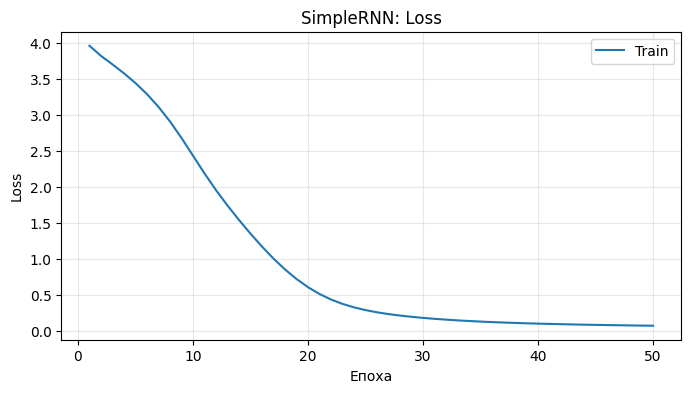

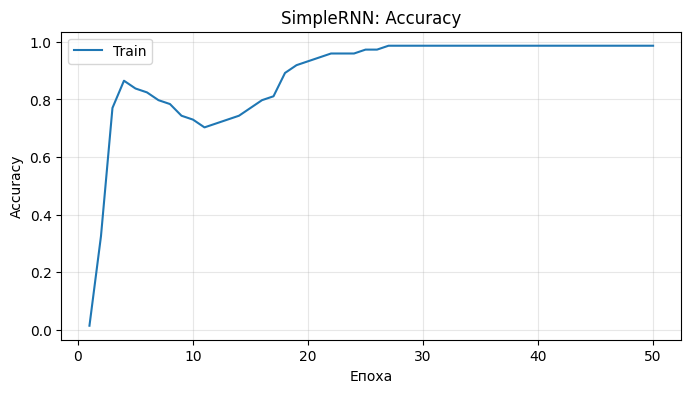

In [4]:
def plot_history(history, name):
    for metric, ylabel in [('loss', 'Loss'), ('accuracy', 'Accuracy')]:
        plt.figure(figsize=(8, 4))
        values = history.history[metric]
        plt.plot(range(1, len(values)+1), values, label='Train')
        if 'val_'+metric in history.history:
            v = history.history['val_'+metric]
            plt.plot(range(1, len(v)+1), v, label='Validation')
        plt.xlabel('Епоха')
        plt.ylabel(ylabel)
        plt.title(f'{name}: {ylabel}')
        plt.grid(alpha=0.3)
        plt.legend()
        plt.show()

plot_history(history, 'SimpleRNN')

## Завдання 3. Генерація тексту
На кожному кроці модель отримує останні три слова, прогнозує наступне, додає його до послідовності та повторює процес. Використовуємо argmax — вибір найімовірнішого слова. Індекси 0 та OOV виключаємо з генерації.

In [5]:
def buildPhrase(text, str_len=20, model=model, window=inp_words):
    data = tokenizer.texts_to_sequences([text])[0]
    if len(data) < window:
        raise ValueError(f'Введіть щонайменше {window} слів')
    result = text.strip()
    for _ in range(str_len):
        inp = np.array([data[-window:]], dtype=np.int32)
        pred = model.predict(inp, verbose=0)[0].copy()
        pred[0] = -1
        pred[tokenizer.word_index[tokenizer.oov_token]] = -1
        indx = int(np.argmax(pred))
        data.append(indx)
        result += ' ' + tokenizer.index_word[indx]
    return result

print(buildPhrase('Думи мої думи'))
print(buildPhrase('Чом вас вітер', str_len=12))

Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину
Чом вас вітер не розвіяв в степу як пилину чом вас лихо не приспало як


**Для обговорення:** чому модель іноді повторює слова? Чому інший початок фрази може давати нелогічний результат?

Модель іноді повторює слова, оскільки навчається на невеликому обсязі тексту та запам'ятовує окремі послідовності. Інший початок фрази може давати нелогічний результат, тому що прогноз залежить від трьох попередніх слів.

## Завдання 4. LSTM та GRU. Порівняння моделей
Замінимо рекурентний шар, залишивши однакові розмірності Embedding, прихованого стану, кількість епох і дані. LSTM використовує окремий стан пам’яті та три вентилі; GRU — два вентилі без окремого стану комірки. Кількість параметрів моделей різна.

In [6]:
models = {'SimpleRNN': model}
histories = {'SimpleRNN': history}
for name, layer in [('LSTM', LSTM), ('GRU', GRU)]:
    tf.keras.utils.set_random_seed(42)
    models[name] = make_model(layer, window=inp_words)
    models[name].summary()
    histories[name] = models[name].fit(X, Y, epochs=50, batch_size=32, verbose=0)
    print(name, buildPhrase('Думи мої думи', model=models[name]))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 256)         │        13,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 52)             │         6,708 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 217,140 (848.20 KB)

 Trainable params: 217,140 (848.20 KB)

 Non-trainable params: 0 (0.00 B)

LSTM Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину


... (2 outputs left out)

 Total params: 168,244 (657.20 KB)

 Trainable params: 168,244 (657.20 KB)

 Non-trainable params: 0 (0.00 B)

GRU Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину


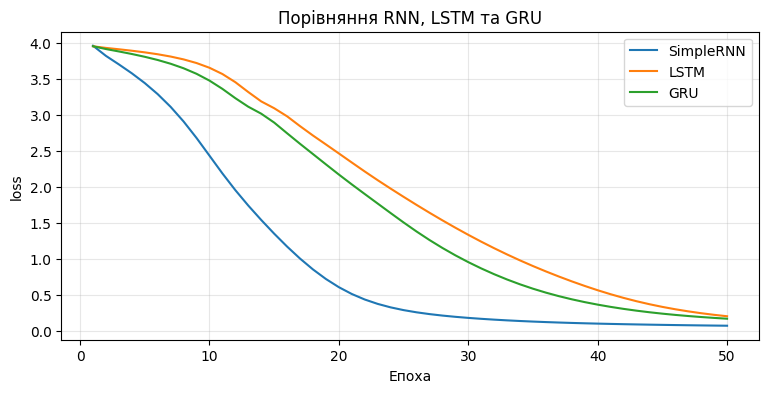

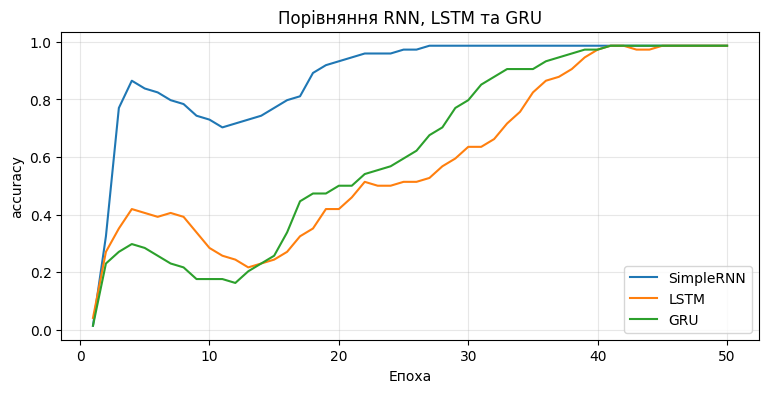

,Модель,Параметри,Train loss,Train accuracy
0,SimpleRNN,69300,0.066617,0.986486
1,LSTM,217140,0.198417,0.986486
2,GRU,168244,0.164280,0.986486


In [7]:
for metric in ['loss', 'accuracy']:
    plt.figure(figsize=(9, 4))
    for name, hist in histories.items():
        values = hist.history[metric]
        plt.plot(range(1, len(values)+1), values, label=name)
    plt.xlabel('Епоха')
    plt.ylabel(metric)
    plt.title('Порівняння RNN, LSTM та GRU')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

import pandas as pd
pd.DataFrame([
    {'Модель': name, 'Параметри': models[name].count_params(),
     'Train loss': h.history['loss'][-1], 'Train accuracy': h.history['accuracy'][-1]}
    for name, h in histories.items()
])

### Аналіз результатів
Порівняйте криві, швидкість зменшення втрат і кількість параметрів. Найвища навчальна accuracy не гарантує найкращої генерації на нових текстах. Для повноцінної перевірки потрібен більший корпус та окрема валідаційна вибірка без перетину текстових фрагментів.

Усі три моделі досягли однакової точності 98,65%. Найменше значення loss отримала SimpleRNN (0,0666), а найбільше — LSTM (0,1984). SimpleRNN має найменшу кількість параметрів (69 300), GRU — 168 244, LSTM — 217 140. Отже, SimpleRNN показала найкращий результат за навчальними показниками, але це не гарантує найякіснішої генерації тексту.

## Завдання 5. Самостійна робота
Оберіть інший український текст (бажано значно довший за наведений приклад). Побудуйте власну модель прогнозування наступного слова. Усі наступні клітинки коду залишено порожніми навмисно.

### 5.1. Підготовка даних
Завантажте текст, створіть токенізатор, сформуйте вікна з 5 слів. За можливості розділіть текст на навчальну та валідаційну частини **до** формування вікон; навчіть токенізатор лише на навчальній частині.

In [8]:
text = """# Кіт у чоботях

Один мірошник залишив у спадщину трьом своїм синам тільки млин, осла і кота. Сини швидко поділили спадщину: старший забрав собі млин, середній одержав осла, а меншому дістався кіт.

Менший брат дуже засмутився.

— Мої брати, — казав він, — зможуть чесно заробити собі на хліб, якщо житимуть разом. А мені, бідолашному, коли я з’їм кота і зроблю рукавички з його шкури, лишиться тільки померти голодною смертю.

Кіт почув ті слова, але нітрохи не збентежився.

— Не журіться, хазяїне, — сказав він з поважним і серйозним виглядом. — Приготуйте мені торбинку та замовте пару добрих чобіт, щоб зручніше було ходити по чагарниках, і ви самі скоро переконаєтесь, що ваша частка не така вже й погана, як це може здатися на перший погляд.

Спочатку менший брат не надав цьому особливого значення, але, згадавши, як, ловлячи щурів та мишей, кіт удається до різних спритних витівок і хитрощів — звисає догори ногами, ховається в борошно і прикидається неживим, — він подумав:

«А що, коли й справді кіт допоможе мені в біді?»

Як тільки кіт одержав усе, що просив, він узув чоботи, перекинув торбинку через плече, взяв шворки в передні лапи й подався в гайок, де було дуже багато кролів.

Кіт поклав у торбинку висівок та заячої капусти і ліг у кущах, ніби мертвий, очікуючи, щоб який-небудь молодий, недосвідчений і легковажний кріль поткнувся в його торбинку поласувати тим, що в ній було.

Ледве він ліг, як молоде дурненьке кроленя, спокусившись висівками, залізло в торбинку. В ту ж мить кіт спритно затяг шворки, схопив кроленя й убив його без жалю.

Дуже гордий зі своєї здобичі, кіт пішов у палац і попросив, щоб про нього доповіли королю.

Кота ввели до королівських покоїв. Там він низько вклонився королю і сказав:

— Ваша величносте! Мій пан маркіз Карабас (таке чудне ім’я вигадав кіт своєму хазяїнові) звелів мені піднести вам ось цього кроля зі свого садка.

— Скажи своєму хазяїнові, — відповів король, — що я йому дуже вдячний і задоволений з такого подарунка.

Кіт ввічливо попрощався і пішов геть.

Іншим разом він сховався в житі, так само розклав свою торбинку і, тільки-но дві цікаві куріпки забралися в неї, смикнув за шворки і впіймав обох.

Тоді він знову пішов у палац до короля і підніс йому птахів.

Король з задоволенням узяв куріпок і звелів почастувати кота парою мишей.

Так час від часу протягом двох чи трьох місяців кіт приносив королю дичину, яку нібито вбивав на полюванні або розводив у садках його хазяїн.

Одного разу, довідавшись про те, що король разом із своєю дочкою, найвродливішою принцесою в світі, їде на прогулянку берегом річки, кіт прибіг до свого хазяїна і сказав йому:

— Якщо ви послухаєте моєї поради, то будете щасливі все життя. Вам треба лише викупатися в річці у тому місці, де я покажу, а все інше я вже влаштую сам.

Маркіз Карабас зробив усе так, як йому порадив кіт, не здогадуючись, навіщо це потрібно.

Саме коли він купався, берегом річки проїздив у своїй кареті король.

Кіт уже чатував на нього, вискочив на дорогу і щосили закричав:

— Рятуйте! Рятуйте! Маркіз Карабас потопає!

Король, почувши цей відчайдушний крик, визирнув з карети. Він одразу ж упізнав кота, який не раз приносив йому в подарунок дичину, і наказав своїй варті бігти на допомогу маркізові Карабасу.

Поки бідолашного маркіза витягали з річки, кіт підійшов до карети і розповів королю, що в той час, як його хазяїн купався, з’явилися злодії і вкрали весь одяг, хоч він, кіт, і кричав щосили: «Ловіть злодіїв!» Насправді ж хитрун сховав одяг свого хазяїна в кущах під великим каменем.

Король негайно наказав своїм придворним принести для маркіза Карабаса одне з найкращих своїх убрань і був надзвичайно ласкавий до нього.

Принцесі маркіз теж дуже сподобався: адже він був гарний і стрункий хлопець, чудовий королівський одяг був йому дуже до лиця, а ніжний і шанобливий погляд красномовніше за будь-які слова промовляв про його лагідну вдачу.

Король запропонував маркізу сісти в карету і поїхати з ними на прогулянку.

А кіт, дуже радий з того, що його хитрощі починають потроху вдаватися, побіг уперед.

Побачивши селян, що косили на луках, він озвався до них:

— Глядіть мені, люди добрі, якщо ви не скажете королю, що ці луки належать маркізові Карабасу, вас усіх порубають, як начинку до пирога!

Коли карета під’їхала до косарів, король, звичайно, спитав, чиї луки вони косять.

— Це луки маркіза Карабаса, — відповіли косарі в один голос, бо кіт дуже налякав їх своїми погрозами.

— У вас тут чудовий маєток, — прихильно сказав король маркізові Карабасу.

— Так, ваша величносте, — відповів маркіз, — щороку на цих луках прекрасний сінокіс.

А кіт, що біг попереду, зустрів невдовзі женців та й каже:

— Глядіть мені, люди добрі, якщо ви не скажете, що ця нива належить маркізові Карабасу, вас усіх порубають, як начинку до пирога!

Король, що під’їхав за хвилину до женців, захотів узнати, чия то нива.

— Маркіза Карабаса, — відповіли женці в один голос, і король знову був задоволений, так само, як і маркіз.

А кіт, забувши про втому, біг попереду карети і всім, кого зустрічав по дорозі, наказував одне й те ж саме, так що король був дуже задоволений, що у маркіза Карабаса такі великі володіння.

Нарешті кіт прибіг до чудового замку, що належав страшному людожерові. Той людожер був надзвичайно багатий: саме він був господарем усіх земель, через які щойно проїздив король.

Кіт розпитав, хто той людожер та що він уміє робити, і попросив дозволу ввійти в замок та віддати шану його хазяїнові.

Людожер зустрів кота з усією ввічливістю, на яку тільки здатні людожери, і запропонував йому відпочити.

Кіт погодився і сказав:

— Мене запевняли, ніби ви вмієте обертатися на будь-яку тварину і легко можете, наприклад, обернутися на лева або слона. Чи так це?

— Авжеж, — відповів людожер грубим голосом, — і щоб довести вам, що це правда, я зараз обернуся на лева.

Вдарившись об підлогу, людожер в одну мить обернувся на величезного лева.

Кіт так перелякався, побачивши перед собою страшного звіра, що й незчувся, як здерся на ринву, хоч це було важко і небезпечно, бо він був у чоботях, а в них не так уже й просто дряпатись по дахах.

Та, помітивши, що людожер прибрав свого попереднього вигляду, переляканий кіт, тремтячи, зліз з ринви і признався, що потерпав од страху.

Людожер голосно зареготав у відповідь.

— Мене також запевняли, — сказав кіт, — ніби ви вмієте обертатися і на дрібних тварин, наприклад, на щура або мишу. Як по правді, я вважаю, що це неможливо.

— Неможливо? — перепитав людожер. — Ну так дивіться!

І в ту ж мить він обернувся на малесеньку мишу, яка хутко забігала по підлозі.

А кіт, тільки-но побачив мишу, накинувся на неї і з’їв.

Тим часом король, проїжджаючи мимо, звернув увагу на чудовий замок людожера і захотів оглянути його.

Кіт почув гуркіт карети, кинувся назустріч і сказав королю:

— Прошу ласкаво, ваша величносте, до замку маркіза Карабаса!

— Як, пане маркіз, — вигукнув здивований король, — цей замок також належить вам?! Я ніде не бачив нічого кращого за це подвір’я і за будівлі, що оточують його! Огляньмо їх всередині, будь ласка!

Маркіз подав руку молодій принцесі, і вони пішли слідом за королем.

Гості ввійшли у велику залу, де побачили чудово прибраний стіл: людожер саме чекав своїх друзів, які, довідавшись, що приїхав король, поспішили непомітно втекти.

Завваживши, якими закоханими очима позирала на маркіза Карабаса принцеса, король, захоплений його багатством, сказав:

— Якщо хочете, пане маркіз, ви можете стати моїм зятем!

Маркіз низько вклонився, подякував королю за честь і того ж дня одружився з принцесою.

А кіт став дуже поважною особою і полював з того часу на мишей тільки задля розваги."""

text = text.lower().strip()

In [9]:
words = text.split()

split_idx = int(len(words) * 0.8)

train_text = " ".join(words[:split_idx])
val_text = " ".join(words[split_idx:])

print("Кількість слів у тексті:", len(words))
print("Слів у навчальній частині:", len(train_text.split()))
print("Слів у валідаційній частині:", len(val_text.split()))

Кількість слів у тексті: 1248
Слів у навчальній частині: 998
Слів у валідаційній частині: 250


In [10]:
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts([train_text])

train_seq = tokenizer.texts_to_sequences([train_text])[0]
val_seq = tokenizer.texts_to_sequences([val_text])[0]

vocab_size = len(tokenizer.word_index) + 1

print("Розмір словника:", vocab_size)
print("Навчальна послідовність:", len(train_seq))
print("Валідаційна послідовність:", len(val_seq))

Розмір словника: 534
Навчальна послідовність: 1003
Валідаційна послідовність: 251


In [11]:
import numpy as np

inp_words = 5

def create_sequences(sequence, window):
    X, Y = [], []

    for i in range(len(sequence) - window):
        X.append(sequence[i:i + window])
        Y.append(sequence[i + window])

    return np.array(X), np.array(Y)

X_train, Y_train = create_sequences(train_seq, inp_words)
X_val, Y_val = create_sequences(val_seq, inp_words)

print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_val:", X_val.shape)
print("Y_val:", Y_val.shape)

X_train: (998, 5)
Y_train: (998,)
X_val: (246, 5)
Y_val: (246,)


### 5.2. Побудова моделей
Створіть три моделі: SimpleRNN, LSTM і GRU з Embedding. Встановіть розмірність Embedding 128 та 64 рекурентні нейрони. Виведіть summary кожної моделі.

In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, GRU, Dense

In [13]:
def make_model(layer_class):
    model = Sequential([
        Input(shape=(inp_words,), dtype='int32'),
        Embedding(input_dim=vocab_size, output_dim=128),
        layer_class(64, activation='tanh'),
        Dense(vocab_size, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [14]:
rnn_model = make_model(SimpleRNN)
lstm_model = make_model(LSTM)
gru_model = make_model(GRU)

In [15]:
print("SimpleRNN model:")
rnn_model.summary()

print("\nLSTM model:")
lstm_model.summary()

print("\nGRU model:")
gru_model.summary()

SimpleRNN model:


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 5, 128)         │        68,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 534)            │        34,710 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 115,414 (450.84 KB)

 Trainable params: 115,414 (450.84 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 5, 128)         │        68,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 534)            │        34,710 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 140,310 (548.09 KB)

 Trainable params: 140,310 (548.09 KB)

 Non-trainable params: 0 (0.00 B)

### 5.3. Навчання
Навчіть усі три моделі протягом 50 епох. Використайте однакові параметри навчання та збережіть історії. За наявності валідаційної вибірки передайте її через validation_data.

In [16]:
epochs = 50
batch_size = 32

rnn_history = rnn_model.fit(
    X_train, Y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val, Y_val),
    verbose=1
)

lstm_history = lstm_model.fit(
    X_train, Y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val, Y_val),
    verbose=1
)

gru_history = gru_model.fit(
    X_train, Y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val, Y_val),
    verbose=1
)

Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.0160 - loss: 6.2724 - val_accuracy: 0.0081 - val_loss: 6.2608
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.0942 - loss: 6.0596 - val_accuracy: 0.0122 - val_loss: 6.4303
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.0581 - loss: 5.7118 - val_accuracy: 0.0488 - val_loss: 6.5795
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0862 - loss: 5.4584 - val_accuracy: 0.0528 - val_loss: 6.5691
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.1453 - loss: 5.1238 - val_accuracy: 0.0447 - val_loss: 6.4028
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.2325 - loss: 4.7848 - val_accuracy: 0.0203 - val_loss: 6.3350
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2986 - loss: 4.4548 - val_accuracy: 0.0163 - val_loss: 6.3429
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3627 - loss: 4.1302 - val_accuracy: 0.0163 - val

In [17]:
print("SimpleRNN:", len(rnn_history.history['loss']), "епох")
print("LSTM:", len(lstm_history.history['loss']), "епох")
print("GRU:", len(gru_history.history['loss']), "епох")

SimpleRNN: 50 епох
LSTM: 50 епох
GRU: 50 епох


### 5.4. Графіки
Побудуйте графіки Loss та Accuracy для трьох моделей. Якщо використано валідацію, додайте Validation Loss та Validation Accuracy.

In [18]:
import matplotlib.pyplot as plt

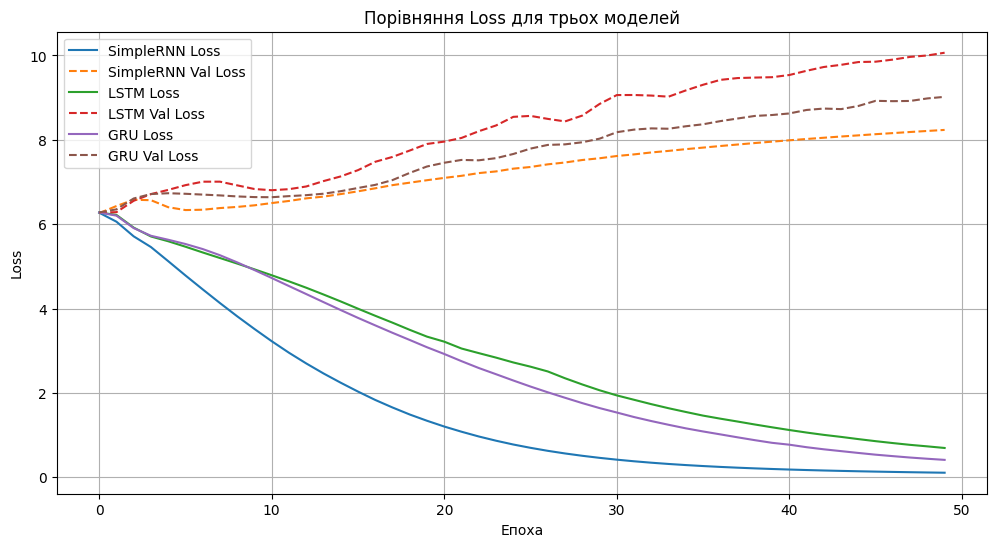

In [19]:
plt.figure(figsize=(12, 6))

plt.plot(rnn_history.history['loss'], label='SimpleRNN Loss')
plt.plot(rnn_history.history['val_loss'], '--', label='SimpleRNN Val Loss')

plt.plot(lstm_history.history['loss'], label='LSTM Loss')
plt.plot(lstm_history.history['val_loss'], '--', label='LSTM Val Loss')

plt.plot(gru_history.history['loss'], label='GRU Loss')
plt.plot(gru_history.history['val_loss'], '--', label='GRU Val Loss')

plt.title('Порівняння Loss для трьох моделей')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

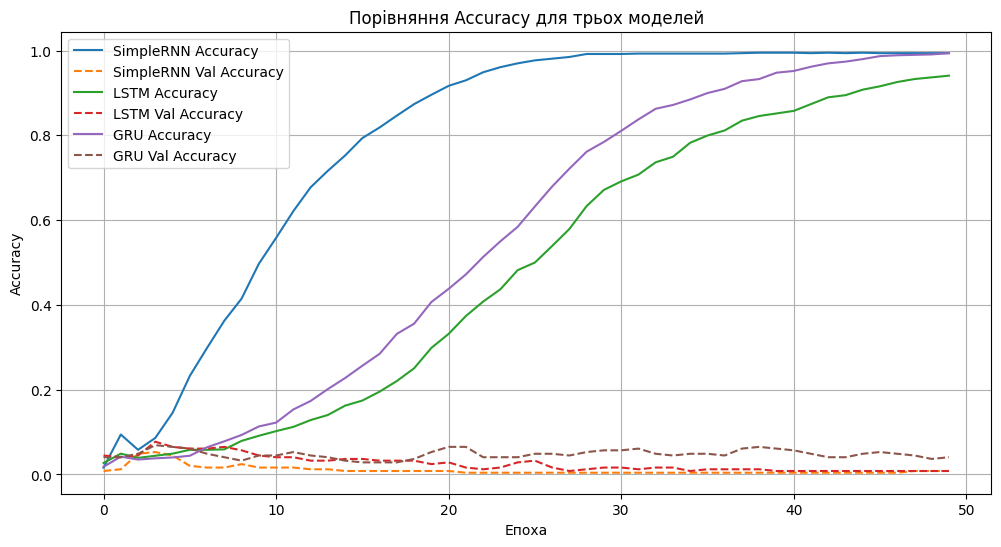

In [20]:
plt.figure(figsize=(12, 6))

plt.plot(rnn_history.history['accuracy'], label='SimpleRNN Accuracy')
plt.plot(rnn_history.history['val_accuracy'], '--', label='SimpleRNN Val Accuracy')

plt.plot(lstm_history.history['accuracy'], label='LSTM Accuracy')
plt.plot(lstm_history.history['val_accuracy'], '--', label='LSTM Val Accuracy')

plt.plot(gru_history.history['accuracy'], label='GRU Accuracy')
plt.plot(gru_history.history['val_accuracy'], '--', label='GRU Val Accuracy')

plt.title('Порівняння Accuracy для трьох моделей')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

### 5.5. Генерація та порівняння
Реалізуйте функцію генерації. Для кожної моделі згенеруйте по 20 слів із двох початкових фраз довжиною не менше п’яти слів. Сформуйте таблицю порівняння моделей.

In [21]:
def generate_text(model, seed_text, num_words=20):
    sequence = tokenizer.texts_to_sequences([seed_text.lower()])[0]
    generated = sequence.copy()

    for _ in range(num_words):
        input_seq = np.array([generated[-inp_words:]])
        prediction = model.predict(input_seq, verbose=0)[0]
        prediction[0] = 0

        next_word_id = np.argmax(prediction)
        generated.append(next_word_id)

    result = [tokenizer.index_word.get(idx, "<OOV>") for idx in generated]

    return " ".join(result)

In [22]:
seed_phrases = [
    "Один мірошник залишив у спадщину трьом своїм",
    "Кіт почув ті слова але нітрохи не збентежився"
]

In [23]:
models = {
    "SimpleRNN": rnn_model,
    "LSTM": lstm_model,
    "GRU": gru_model
}

results = []

for phrase in seed_phrases:
    for model_name, model in models.items():
        generated_text = generate_text(model, phrase, num_words=20)

        results.append({
            "Початкова фраза": phrase,
            "Модель": model_name,
            "Згенерований текст": generated_text
        })

In [24]:
import pandas as pd

comparison_df = pd.DataFrame(results)

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)

display(comparison_df)

,Початкова фраза,Модель,Згенерований текст
0,Один мірошник залишив у спадщину трьом своїм,SimpleRNN,один мірошник залишив у спадщину трьом своїм синам тільки млин осла і кота сини швидко поділили спадщину старший забрав собі млин середній одержав осла а меншому дістався
1,Один мірошник залишив у спадщину трьом своїм,LSTM,один мірошник залишив у спадщину трьом своїм синам тільки млин осла і кота сини швидко поділили спадщину старший забрав собі млин млин одержав осла а швидко хазяїнові
2,Один мірошник залишив у спадщину трьом своїм,GRU,один мірошник залишив у спадщину трьом своїм синам тільки млин осла і кота сини швидко поділили спадщину старший забрав собі млин середній одержав осла а меншому дістався
3,Кіт почув ті слова але нітрохи не збентежився,SimpleRNN,кіт почув ті слова але нітрохи не збентежився — не журіться хазяїне — сказав він з поважним і серйозним виглядом — приготуйте мені торбинку та замовте пару добрих
4,Кіт почув ті слова але нітрохи не збентежився,LSTM,кіт почув ті слова але нітрохи не збентежився — не журіться хазяїне — він він з поважним він виглядом виглядом він — кущах та кущах його — —
5,Кіт почув ті слова але нітрохи не збентежився,GRU,кіт почув ті слова але нітрохи не збентежився — не журіться хазяїне — він — рятуйте рятуйте маркіз карабас потопає король почувши цей відчайдушний крик визирнув з карети


### 5.6. Висновки
У клітинці нижче напишіть 5–7 речень: яка модель показала кращий результат, чи спостерігається перенавчання, як довжина вікна та обсяг корпусу впливають на генерацію. Обґрунтуйте висновки графіками та прикладами.

У результаті експерименту найкраще себе показала модель SimpleRNN, оскільки вона генерувала найбільш зв’язний і послідовний текст, близький до оригіналу казки. GRU також продемонструвала непогані результати, тоді як LSTM частіше повторювала слова та створювала нелогічні речення. За графіками Loss та Accuracy можна оцінити, наскільки добре моделі навчалися та чи виникало перенавчання: якщо навчальна помилка зменшується, а валідаційна зростає, це свідчить про перенавчання. Довжина вікна впливає на кількість слів, які модель враховує під час прогнозування: більше вікно дає змогу враховувати ширший контекст, але потребує більшої кількості навчальних даних. Невеликий обсяг корпусу обмежує словниковий запас і кількість прикладів, тому моделі можуть повторювати слова та генерувати нелогічні фрагменти. Це помітно в результатах LSTM, де зустрічаються повтори «він» і «кущах». Отже, для покращення генерації варто використовувати більший навчальний корпус і експериментувати з довжиною вікна.